# Code 1: My first circuit, the Bell state

This notebook goes with [Lecture 2](../content/lectures/lecture2.md). We will:

1. build the Bell-state circuit $H$ on qubit 0 followed by a CNOT,
2. simulate it *exactly* to see the state vector,
3. simulate *measurements* (shots), as a real quantum computer would give us,
4. run the same circuit on a simulated **noisy** IBM device, the final step before running on real hardware.

```{tip}
Run the cells in order with **Shift+Enter**. If something breaks, use *Restart Kernel & Run All*.
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler

## Building the circuit

A `QuantumCircuit(2)` starts with two qubits, both in the state $|0\rangle$. We add gates one at a time, then measure every qubit.

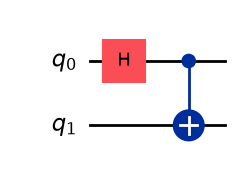

In [2]:
qc = QuantumCircuit(2)
qc.h(0)        # Hadamard on qubit 0
qc.cx(0, 1)    # CNOT: control qubit 0, target qubit 1

qc.draw("mpl")

## The exact state

Before measuring, we can ask the simulator for the full state vector. This is something a real quantum computer can **never** give us directly. We should find $\frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$.

In [3]:
psi = Statevector(qc)
psi.draw("latex")

<IPython.core.display.Latex object>

```{important}
**Qiskit orders qubits right to left.** In the bit string `"01"`, the *rightmost* bit is qubit 0 and the leftmost is qubit 1. So `"01"` means qubit 0 is in $|1\rangle$ and qubit 1 is in $|0\rangle$. The lecture notes write states as $|q_0 q_1\rangle$, i.e. left to right. For the Bell state this makes no difference, but keep it in mind for later!
```

We can check this with a state that isn't symmetric:

In [4]:
test = QuantumCircuit(2)
test.x(0)                      # flip qubit 0 only
Statevector(test).draw("latex")  # Qiskit prints |01>, i.e. |q1 q0>

<IPython.core.display.Latex object>

## Measuring: shots and probabilities

A quantum computer only gives us measurement outcomes. Each run of the circuit (a **shot**) gives one bit string. We estimate probabilities by repeating many times.

In Qiskit, measurements are added explicitly, and circuits are run with a *primitive*. The **Sampler** returns measurement counts.

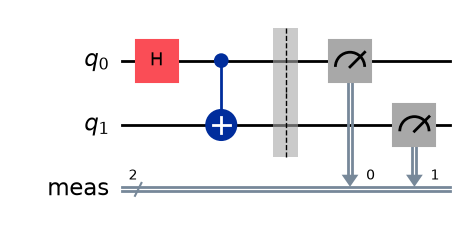

In [5]:
qc_meas = qc.copy()
qc_meas.measure_all()          # measure all qubits into classical bits
qc_meas.draw("mpl")

In [6]:
shots = 8192
sampler = StatevectorSampler(seed=4041)          # seed: reproducible "random" results
job = sampler.run([qc_meas], shots=shots)
counts = job.result()[0].data.meas.get_counts()
print(counts)

{'00': 4156, '11': 4036}


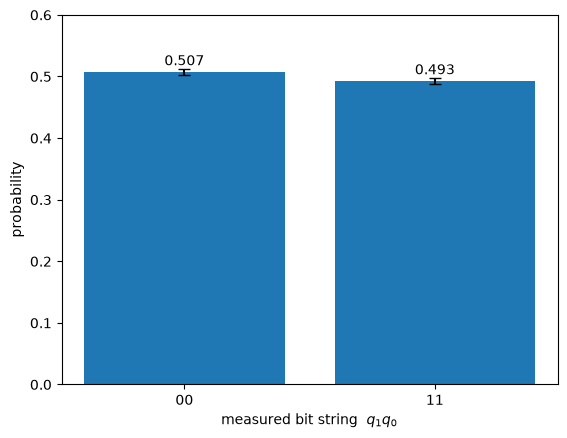

In [7]:
probs = {k: v / shots for k, v in sorted(counts.items())}
errors = {k: np.sqrt(p * (1 - p) / shots) for k, p in probs.items()}  # binomial standard error

fig, ax = plt.subplots()
bars = ax.bar(probs.keys(), probs.values(), yerr=list(errors.values()), capsize=4)
ax.bar_label(bars, fmt="%.3f")
ax.set_xlabel("measured bit string  $q_1 q_0$")
ax.set_ylabel("probability")
ax.set_ylim(0, 0.6)
plt.show()

The probabilities are close to, but not exactly, $0.5$. With $N$ shots the statistical error on a probability $p$ is $\sqrt{p(1-p)/N}\approx 0.006$ here, which is the size of the error bars. Notice that we **never** measure `01` or `10`: the two qubits are perfectly correlated.

````{admonition} Try this
:class: tip
1. Change `shots` to 10, 100 and 100 000. How does the spread around 0.5 change?
2. (Exercise 2.3) Build the 3-qubit GHZ circuit from the lecture notes and check you get only `000` and `111`.
````

In [8]:
# Exercise: build the GHZ state here
ghz = QuantumCircuit(3)
# ... add gates ...

## Towards real hardware: a noisy simulation

Real quantum computers are noisy. Qiskit includes *fake backends*: models of real IBM devices, including their qubit layout, native gates and measured error rates. Running on one is the best way to test code before spending real QPU time.

Two extra steps are needed for any real (or fake) device:

1. **Transpile**: rewrite the circuit using only the device's native gates and the connections between its physical qubits.
2. Run with a sampler attached to that backend.

Native gates used: {'rz': 5, 'sx': 3, 'measure': 2, 'cz': 1, 'barrier': 1}


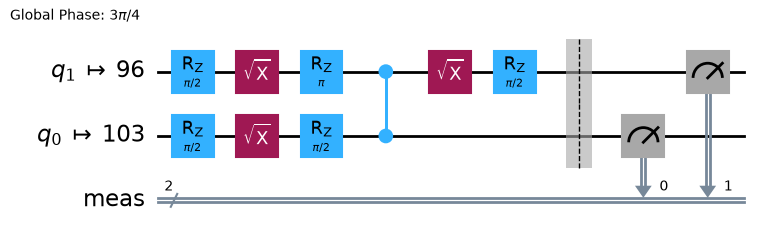

In [9]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeFez

backend = FakeFez()          # a model of a 156-qubit IBM Heron device, including its noise

# 1. Transpile: rewrite the circuit for this device's native gates and qubit layout
pm = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=1)
qc_device = pm.run(qc_meas)
print("Native gates used:", dict(qc_device.count_ops()))
qc_device.draw("mpl", idle_wires=False, fold=-1)

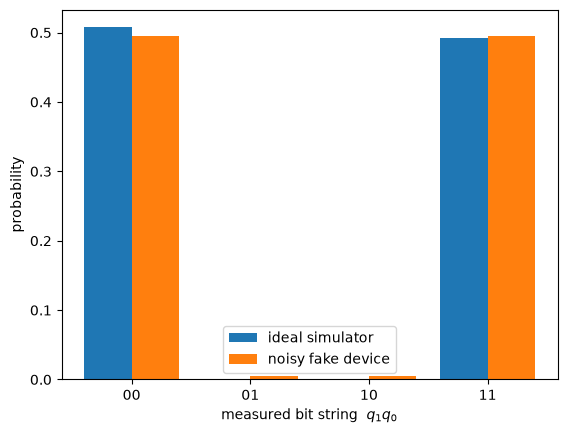

{'00': 0.4951171875, '01': 0.0057373046875, '10': 0.004638671875, '11': 0.4945068359375}


In [10]:
# 2. Run with a Sampler attached to the backend
sampler_dev = Sampler(mode=backend)
sampler_dev.options.simulator.seed_simulator = 4041   # fake backends only: reproducible noise
result = sampler_dev.run([qc_device], shots=shots).result()
counts_noisy = result[0].data.meas.get_counts()

probs_noisy = {k: counts_noisy.get(k, 0) / shots for k in ["00", "01", "10", "11"]}
probs_ideal = {k: probs.get(k, 0) for k in ["00", "01", "10", "11"]}

x = np.arange(4)
fig, ax = plt.subplots()
ax.bar(x - 0.2, probs_ideal.values(), width=0.4, label="ideal simulator")
ax.bar(x + 0.2, probs_noisy.values(), width=0.4, label="noisy fake device")
ax.set_xticks(x, probs_ideal.keys())
ax.set_xlabel("measured bit string  $q_1 q_0$")
ax.set_ylabel("probability")
ax.legend()
plt.show()
print(probs_noisy)

The noisy device now gives a small probability of `01` and `10`. These are errors from imperfect gates and imperfect readout, just like in the real-device results in the lecture notes.

## Running on a real quantum computer

The **only** change needed to run on real hardware is the `backend`. Everything above (transpile, `Sampler(mode=backend)`, `.run`) stays the same. See [Running on real quantum computers](../content/outline/hardwareAccess.md) for how to get a free account and save your token, then:

```python
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()                        # uses your saved token
backend = service.least_busy(operational=True, simulator=False)
print(backend.name)
# ... then re-run the transpile and Sampler cells above
```

Real jobs wait in a queue (minutes to hours), and every second of QPU time counts against your free allocation. **Always test on a fake backend first.**

````{admonition} Try this
:class: tip
Run the GHZ circuit on the fake device. Is the noise worse with three qubits than with two? Why might that be?
````